# Notebook 06 — MuJoCo fundamentals with the SAURCON car

Companion to [Chapter 8](../08_mujoco_simulation.md). We load the generated MJCF, look inside the
compiled model, measure MuJoCo's friction, reproduce the bouncing-cylinder bug, and watch the drive
actuators track a speed ramp.

In [1]:
import os; os.environ.setdefault('MUJOCO_GL', 'egl')          # offscreen rendering (GPU); use 'osmesa' without one
import warnings; warnings.filterwarnings('ignore', message='Unable to import Axes3D')
import sys, math
from pathlib import Path
import numpy as np, matplotlib.pyplot as plt, mujoco
WS = Path('../../..').resolve(); sys.path.insert(0, str(WS / 'src' / 'saurcon_rl'))
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'grid.color': '#e4e3df',
                     'axes.spines.top': False, 'axes.spines.right': False})
BLUE, ORANGE, AQUA, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#52514e'
print('MuJoCo', mujoco.__version__)

MuJoCo 4.0.1


## 1. A model is generated XML

In [2]:
from saurcon_rl.mujoco_model import build_mjcf, ackermann, WHEEL_R, TRACK, WHEELBASE
xml = build_mjcf()
print('\n'.join(xml.splitlines()[:40]))

<mujoco model="saurcon_raceway">
  <compiler angle="radian" autolimits="true"/>
  <option timestep="0.002" integrator="implicitfast"/>
  <visual><global offwidth="960" offheight="540"/><quality shadowsize="2048"/></visual>
  <asset>
    <texture name="grid" type="2d" builtin="checker" rgb1="0.55 0.55 0.53" rgb2="0.5 0.5 0.48" width="512" height="512"/>
    <material name="floor" texture="grid" texrepeat="40 40"/>
    
  </asset>
  <default>
    <default class="wheel">
      <!-- Ellipsoid wheels give a single smooth contact point. (The car once bounced
           off the floor; the cause was the drive gain kv=5, not the wheel shape.) -->
      <geom type="ellipsoid" size="0.033 0.02 0.033" friction="1.4 0.01 0.0001"
            condim="4" contype="1" conaffinity="1" rgba="0.1 0.1 0.1 1"/>
    </default>
    <default class="cone"><geom contype="3" conaffinity="3" friction="0.8 0.01 0.0001"/></default>
  </default>
  <worldbody>
    <light pos="0 0 6" dir="0 0 -1" diffuse="0.8 0.8 0.8"/>

## 2. What MuJoCo compiles it into
State lives in generalised coordinates: `qpos` (7 for the free chassis: position + quaternion, plus one per hinge)
and `qvel` (6 + one per hinge).

In [3]:
m = mujoco.MjModel.from_xml_string(xml); d = mujoco.MjData(m)
print(f'bodies {m.nbody}, joints {m.njnt}, nq {m.nq}, nv {m.nv}, actuators {m.nu}, timestep {m.opt.timestep} s')
print('total mass %.2f kg' % m.body_mass.sum())
for j in range(m.njnt):
    print(f'  joint {mujoco.mj_id2name(m, mujoco.mjtObj.mjOBJ_JOINT, j):18s} type {m.jnt_type[j]}  qpos index {m.jnt_qposadr[j]}')
for a in range(m.nu):
    print(f'  actuator {mujoco.mj_id2name(m, mujoco.mjtObj.mjOBJ_ACTUATOR, a):12s} gain {m.actuator_gainprm[a, 0]:.1f} force range {m.actuator_forcerange[a]}')

bodies 8, joints 7, nq 13, nv 12, actuators 4, timestep 0.002 s
total mass 5.40 kg
  joint car_free           type 0  qpos index 0
  joint left_rear_spin     type 3  qpos index 7
  joint right_rear_spin    type 3  qpos index 8
  joint left_steer         type 3  qpos index 9
  joint left_front_spin    type 3  qpos index 10
  joint right_steer        type 3  qpos index 11
  joint right_front_spin   type 3  qpos index 12
  actuator left_drive   gain 1.0 force range [-2.  2.]
  actuator right_drive  gain 1.0 force range [-2.  2.]
  actuator left_steer   gain 4.0 force range [0. 0.]
  actuator right_steer  gain 4.0 force range [0. 0.]


## 3. Rendering the raceway

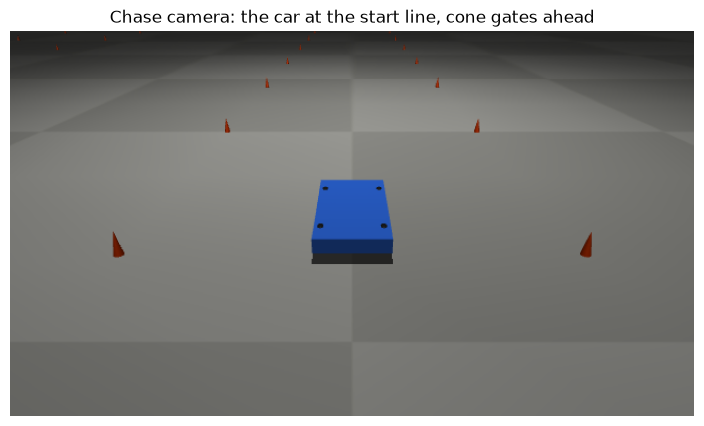

In [4]:
from saurcon_rl.track import Track
tr = Track.from_world(WS / 'src/middle_earth/worlds/racetrack.world')
mt = mujoco.MjModel.from_xml_string(build_mjcf(cones=tr.cones)); dt_ = mujoco.MjData(mt)
dt_.qpos[:3] = [-1.0, 0, 0.006]; mujoco.mj_forward(mt, dt_)
r = mujoco.Renderer(mt, 360, 640); r.update_scene(dt_, camera='chase')
plt.figure(figsize=(9, 5)); plt.imshow(r.render()); plt.axis('off'); plt.title('Chase camera: the car at the start line, cone gates ahead'); plt.show()

## 4. Measuring friction: a block sliding on the floor
A body sliding on a plane should decelerate at $\mu g$. MuJoCo combines the two geoms' friction with the **maximum**.
The block is flat on purpose: a cube with $\mu > 1$ tips over and tumbles instead of sliding (the friction force at its
base exceeds what its weight can resist about the leading edge) — a first version of this test made exactly that mistake.

In [5]:
def slide(mu_block, mu_floor=1.0, v0=3.0):
    xml = f"""<mujoco><option timestep="0.001"/><worldbody>
      <geom type="plane" size="20 20 .1" friction="{mu_floor} 0.005 0.0001"/>
      <body pos="0 0 0.01"><freejoint/><geom type="box" size=".05 .05 .005" mass="1" friction="{mu_block} 0.005 0.0001"/></body>
    </worldbody></mujoco>"""
    mm = mujoco.MjModel.from_xml_string(xml); dd = mujoco.MjData(mm)
    for _ in range(200): mujoco.mj_step(mm, dd)          # settle
    dd.qvel[0] = v0; v = []
    for _ in range(600): mujoco.mj_step(mm, dd); v.append(dd.qvel[0])
    v = np.array(v); moving = v > 0.2                    # fit only while it is still sliding
    return -np.polyfit(np.arange(len(v))[moving]*mm.opt.timestep, v[moving], 1)[0] / 9.81
for mb, mf in ((0.3, 0.3), (0.6, 0.3), (0.3, 0.6), (1.4, 1.0)):
    print(f'block mu {mb}, floor mu {mf}: measured deceleration / g = {slide(mb, mf):.3f}')

block mu 0.3, floor mu 0.3: measured deceleration / g = 0.300
block mu 0.6, floor mu 0.3: measured deceleration / g = 0.598
block mu 0.3, floor mu 0.6: measured deceleration / g = 0.598
block mu 1.4, floor mu 1.0: measured deceleration / g = 1.344


## 5. The hopping car: isolating the cause
The first model's car hopped off the floor at speed. Two things changed in the fix: cylinder wheels became
ellipsoids, and the drive's velocity gain fell from 5 to 1. Which one mattered? Test all four combinations.

cylinder  kv=1: final speed 11.96 m/s, max chassis z    6.0 mm, steps with no contact 0
ellipsoid kv=1: final speed 11.92 m/s, max chassis z    6.0 mm, steps with no contact 0


cylinder  kv=5: final speed  9.16 m/s, max chassis z    6.7 mm, steps with no contact 7
ellipsoid kv=5: final speed  0.97 m/s, max chassis z  156.0 mm, steps with no contact 469


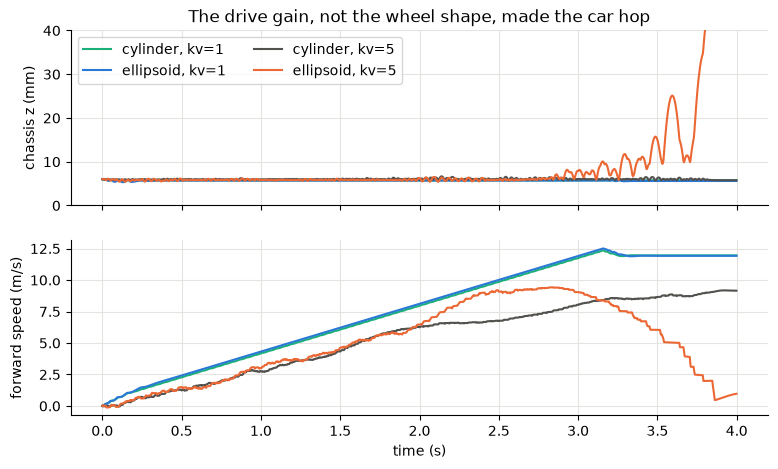

In [6]:
def straight_run(wheel_shape, kv):
    x = build_mjcf().replace('kv="1"', f'kv="{kv}"')
    if wheel_shape == 'cylinder':
        x = x.replace('type="ellipsoid" size="0.033 0.02 0.033"', 'type="cylinder" size="0.033 0.02" euler="1.5708 0 0"')
    mm = mujoco.MjModel.from_xml_string(x); dd = mujoco.MjData(mm)
    v = 0.0; log = []
    for k in range(int(4.0 / mm.opt.timestep)):
        v = min(12.0, v + 3.8 * mm.opt.timestep); w = v / WHEEL_R
        dd.ctrl[:] = [w, w, 0, 0]; mujoco.mj_step(mm, dd)
        log.append((k * mm.opt.timestep, dd.qpos[2], dd.ncon, dd.qvel[0]))
    return np.array(log)
fig, ax = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
for (shape, kv), c in zip((('cylinder', 1), ('ellipsoid', 1), ('cylinder', 5), ('ellipsoid', 5)), (AQUA, BLUE, GREY, ORANGE)):
    L = straight_run(shape, kv)
    ax[0].plot(L[:, 0], 1000 * L[:, 1], color=c, label=f'{shape}, kv={kv}'); ax[1].plot(L[:, 0], L[:, 3], color=c)
    print(f'{shape:9s} kv={kv}: final speed {L[-1, 3]:5.2f} m/s, max chassis z {1000*L[:, 1].max():6.1f} mm, '
          f'steps with no contact {int((L[:, 2] == 0).sum())}')
ax[0].set_ylabel('chassis z (mm)'); ax[0].set_ylim(0, 40); ax[1].set_ylabel('forward speed (m/s)'); ax[1].set_xlabel('time (s)')
ax[0].legend(ncol=2); ax[0].set_title('The drive gain, not the wheel shape, made the car hop'); plt.show()

## 6. Ackermann steering and the drive differential

In [7]:
for delta in (0.1, 0.3, 0.5):
    left, right = ackermann(delta); kappa = math.tan(delta) / WHEELBASE
    print(f'bicycle {delta:.2f} rad -> left {left:.3f}, right {right:.3f} rad; rear wheel speed ratio L/R = '
          f'{(1 - kappa*TRACK/2)/(1 + kappa*TRACK/2):.3f}')

bicycle 0.10 rad -> left 0.103, right 0.097 rad; rear wheel speed ratio L/R = 0.937
bicycle 0.30 rad -> left 0.331, right 0.274 rad; rear wheel speed ratio L/R = 0.817
bicycle 0.50 rad -> left 0.500, right 0.434 rad; rear wheel speed ratio L/R = 0.699


## Exercises
1. Repeat section 4 with `condim="1"` on the block. What happens and why?
2. Change `kv` on the drive actuators to 20 and rerun section 5 with ellipsoids. Plot the drive torque.
3. Render the car mid-corner at 4 m/s from a top-down camera you add to the MJCF.